In [1]:
import arviz as az
import bambi as bmb
import numpy as np
import polars as pl

from matplotlib import pyplot as plt
from kidney.paths import PLOT_DIR

az.rcParams["data.load"] = "eager"

plt.rcParams['pdf.fonttype'] = 42

In [2]:
def plot_measurements(ax, df, ycol="value"):
    groups = ("gtyp", "age", "sex")
    n_group = df.select(pl.struct(*groups).n_unique()).item()
    group_df = (
        df.select(groups).unique()
        .sort(groups)
        .pipe(lambda d: d.with_columns(xtick_x=np.linspace(0, 1, len(d))))
        .with_columns(xtick_label=pl.concat_str(groups, separator=","))
    )
    group_to_x = df.group_by(groups)
    plot_df = (
        df
        .join(group_df, on=groups)
        .sort(groups)
        .with_columns(
            scatter_x=pl.col("xtick_x") + np.random.normal(size=len(df), scale=0.01),
            color=pl.when(gtyp="fa/+").then(pl.lit("black")).otherwise(pl.lit("red")),
            marker=pl.when(sex="M").then(pl.lit("^")).otherwise(pl.lit("o")),
        )
    )
    for _, subdf in plot_df.group_by("sex", maintain_order=True):
        ax.scatter(subdf["scatter_x"], subdf[ycol], 10, color=subdf["color"], marker=subdf["marker"][0])
    ax.set_xticks(group_df["xtick_x"], group_df["xtick_label"], fontsize="x-small");
    return ax, plot_df


## Combined PPC plots
One figure containing all eight variable-specific posterior predictive checks.

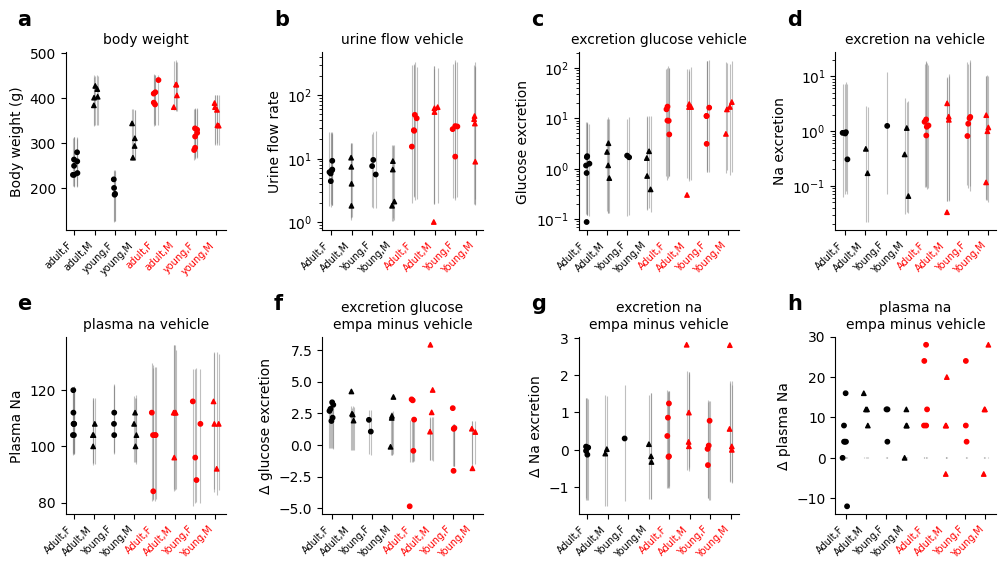

In [14]:
# Combined posterior predictive checks (all variables in this notebook)
# Each panel shows measurements (points) and 95% posterior predictive intervals (grey lines).

ppc_specs = [
    # dataset name, response in posterior_predictive, measurement column, panel label, log-scale
    ("body_weight",                         "weight",    "weight", "Body weight (g)", False),
    ("urine_flow_vehicle",                  "log_value", "value",  "Urine flow rate", True),
    ("excretion_glucose_vehicle",           "log_value", "value",  "Glucose excretion", True),
    ("excretion_na_vehicle",                "log_value", "value",  "Na excretion", True),
    ("plasma_na_vehicle",                   "log_value", "value",  "Plasma Na", False),
    ("excretion_glucose_empa_minus_vehicle", "value",     "value",  "\u0394 glucose excretion", False),
    ("excretion_na_empa_minus_vehicle",      "value",     "value",  "\u0394 Na excretion", False),
    ("plasma_na_empa_minus_vehicle",         "value",     "value",  "\u0394 plasma Na", False),
]

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
plt.subplots_adjust(wspace=0.6, hspace=0.6)

for ax, (variable, posterior_col, obs_col, ylabel, log_scale) in zip(axes.flat, ppc_specs):
    measurements = pl.read_csv(f"../data/prepared/{variable}.csv")
    posterior = az.from_netcdf(f"../results/idata_{variable}.nc")
    lower, upper = (
        posterior.posterior_predictive[posterior_col]
        .quantile([0.025, 0.975], dim=["chain", "draw"])
        .to_numpy()
    )

    # Back-transform predictions from log units to measurement units.
    if posterior_col == "log_value":
        lower, upper = np.exp(lower), np.exp(upper)

    # Attach intervals BEFORE plot_measurements sorts the observations;
    # this retains the correct correspondence between points and intervals.
    if len(measurements) != len(lower):
        raise ValueError(f"{variable}: observations and PPC intervals have different lengths")
    measurements = measurements.with_columns(
        pl.Series("_ppc_lower", lower),
        pl.Series("_ppc_upper", upper),
    )

    ax, plotted = plot_measurements(ax, measurements, ycol=obs_col)
    ax.vlines(
        plotted["scatter_x"].to_numpy(),
        plotted["_ppc_lower"].to_numpy(),
        plotted["_ppc_upper"].to_numpy(),
        color="gray", alpha=0.5, linewidth=0.8, zorder=-1,
    )

    if log_scale:
        ax.set_yscale("log")
    ax.set_title(variable.replace("_", " "), fontsize=10)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("")
    ax.tick_params(axis="x", labelrotation=45, labelsize=7)
    for lbl in ax.get_xticklabels():
        lbl.set_ha("right")
    ax.spines[["top", "right"]].set_visible(False)

    # Get original tick positions and labels
    ticks = ax.get_xticks()
    original_labels = [lbl.get_text() for lbl in ax.get_xticklabels()]
    
    # Remove genotype names
    new_labels = [
        label.replace("fa/fa", "").replace("fa/+", "").strip(" ,")
        for label in original_labels
    ]
    
    # Set new labels
    ax.set_xticks(ticks, labels=new_labels)
    
    # Format and color based on ORIGINAL labels
    ax.tick_params(axis="x", labelrotation=45, labelsize=7)
    
    for lbl, original in zip(ax.get_xticklabels(), original_labels):
        lbl.set_ha("right")
        lbl.set_color("red" if "fa/fa" in original else "black")

for i in [1,2,3]:
    axes[1,i].set_title(axes[1,i].get_title().replace(' empa', '\nempa'), fontsize=10)

for label, ax in zip("abcdefgh", axes.ravel()):
    ax.text(-0.3,1.15,s=label,weight='bold', fontsize=15, transform=ax.transAxes)

fig.savefig(PLOT_DIR / "ppc_biochem_bodyweight_combined.pdf", bbox_inches="tight")


## Separate PPC plots

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,258.777,9.066,241.222,275.167,0.173,0.141,2758.0,2859.0,1.0
gtyp[fa/fa],137.159,13.790,110.115,161.979,0.286,0.226,2333.0,2492.0,1.0
age[young],-75.347,11.866,-97.073,-52.713,0.234,0.229,2599.0,2641.0,1.0
sex[M],136.053,11.544,113.304,156.494,0.225,0.179,2630.0,2671.0,1.0
"gtyp:age[fa/fa, young]",1.838,16.590,-30.450,32.666,0.336,0.343,2448.0,2366.0,1.0
"gtyp:sex[fa/fa, M]",-105.916,16.480,-136.023,-73.808,0.334,0.258,2438.0,2351.0,1.0


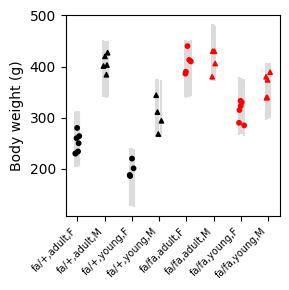

In [3]:
variable = "body_weight"

msts = pl.read_csv(f"../data/prepared/{variable}.csv")
idata = az.from_netcdf(f"../results/idata_{variable}.nc")

display(az.summary(idata, var_names=["~mu", "~sigma"]))

qlow, qhigh = (
    idata.posterior_predictive["weight"]
    .quantile([0.025, 0.975], dim=["chain", "draw"])
    .to_numpy()
)

f, ax = plt.subplots(figsize=(3, 3))

ax, plot_df = plot_measurements(ax, msts, ycol="weight")

ax.vlines(
    plot_df["scatter_x"],
    qlow,
    qhigh,
    zorder=-1,
    color="gainsboro",
)

ax.set_ylabel("Body weight (g)")
ax.set_xlabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

# plt.savefig(PLOT_DIR / 'ppc_body_weight.pdf', bbox_inches='tight')

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,1.908,0.228,1.459,2.322,0.004,0.004,3182.0,2002.0,1.0
gtyp[fa/fa],1.377,0.505,0.459,2.361,0.010,0.009,2370.0,2426.0,1.0
age[Young],-0.033,0.317,-0.648,0.533,0.006,0.006,3169.0,2799.0,1.0
sex[M],-0.423,0.303,-0.990,0.157,0.006,0.006,2696.0,2107.0,1.0
"gtyp:age[fa/fa, Young]",0.053,0.655,-1.150,1.312,0.012,0.011,2953.0,2713.0,1.0
"gtyp:sex[fa/fa, M]",0.332,0.628,-0.773,1.536,0.012,0.010,2647.0,2655.0,1.0
sigma_Intercept,-0.522,0.203,-0.874,-0.109,0.004,0.003,3308.0,2646.0,1.0
sigma_gtyp[fa/fa],0.617,0.271,0.141,1.173,0.005,0.005,3432.0,2591.0,1.0


Text(0, 0.5, 'Ln[Urine flow rate]')

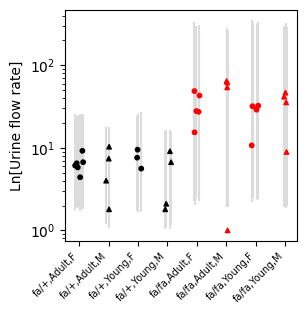

In [4]:
variable = "urine_flow_vehicle"
msts = pl.read_csv(f"../data/prepared/{variable}.csv")
idata = az.from_netcdf(f"../results/idata_{variable}.nc")
display(az.summary(idata, var_names=["~mu", "~sigma"]))
qlow, qhigh = idata.posterior_predictive["log_value"].quantile([0.025, 0.975], dim=["chain", "draw"]).to_numpy()

f, ax = plt.subplots(figsize=(3, 3))
ax, plot_df = plot_measurements(ax, msts)
ax.vlines(plot_df["scatter_x"], np.exp(qlow), np.exp(qhigh), zorder=-1, color="gainsboro");
ax.semilogy();
plt.xticks(rotation=45, ha="right");
ax.set_ylabel("Ln[Urine flow rate]")
# plt.savefig(PLOT_DIR / 'ppc_urine_flow_rate.pdf', bbox_inches='tight')

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,-0.025,0.373,-0.686,0.725,0.007,0.006,2987.0,2746.0,1.0
gtyp[fa/fa],2.149,0.578,1.071,3.205,0.012,0.009,2521.0,2670.0,1.0
age[Young],0.097,0.521,-0.872,1.070,0.010,0.012,2806.0,2734.0,1.0
sex[M],0.180,0.503,-0.762,1.138,0.010,0.009,2396.0,2442.0,1.0
"gtyp:age[fa/fa, Young]",0.173,0.759,-1.276,1.562,0.015,0.014,2548.0,2639.0,1.0
"gtyp:sex[fa/fa, M]",-0.244,0.740,-1.595,1.120,0.015,0.011,2512.0,2688.0,1.0
sigma_Intercept,-0.044,0.200,-0.415,0.336,0.004,0.004,3025.0,2327.0,1.0
sigma_gtyp[fa/fa],0.166,0.270,-0.375,0.632,0.005,0.004,3152.0,2808.0,1.0


Text(0, 0.5, 'Ln[Glucose excretion]')

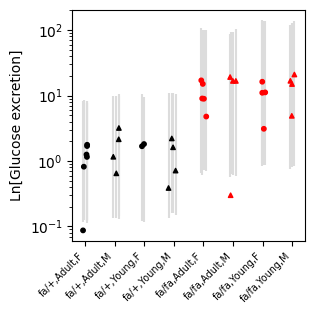

In [5]:
variable = "excretion_glucose_vehicle"
msts = pl.read_csv(f"../data/prepared/{variable}.csv")
idata = az.from_netcdf(f"../results/idata_{variable}.nc")
display(az.summary(idata, var_names=["~mu", "~sigma"]))
qlow, qhigh = idata.posterior_predictive["log_value"].quantile([0.025, 0.975], dim=["chain", "draw"]).to_numpy()

f, ax = plt.subplots(figsize=(3, 3))
ax, plot_df = plot_measurements(ax, msts)
ax.vlines(plot_df["scatter_x"], np.exp(qlow), np.exp(qhigh), zorder=-1, color="gainsboro");
ax.semilogy();
plt.xticks(rotation=45, ha="right");
ax.set_ylabel("Ln[Glucose excretion]")
# plt.savefig(PLOT_DIR / 'ppc_glc_excretion.pdf', bbox_inches='tight')

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,-0.303,0.500,-1.234,0.610,0.009,0.012,2967.0,2624.0,1.0
gtyp[fa/fa],0.541,0.692,-0.773,1.788,0.014,0.015,2625.0,2230.0,1.0
age[Young],0.253,0.718,-1.013,1.674,0.016,0.017,2059.0,2108.0,1.0
sex[M],-1.051,0.714,-2.336,0.329,0.017,0.017,1867.0,1907.0,1.0
"gtyp:age[fa/fa, Young]",-0.215,0.918,-1.895,1.528,0.020,0.017,2187.0,2151.0,1.0
"gtyp:sex[fa/fa, M]",0.478,0.927,-1.159,2.342,0.022,0.018,1780.0,2041.0,1.0
sigma_Intercept,-0.024,0.271,-0.521,0.479,0.006,0.005,2491.0,2163.0,1.0
sigma_gtyp[fa/fa],0.188,0.324,-0.421,0.815,0.006,0.005,2990.0,2784.0,1.0


Text(0, 0.5, 'Ln[Na excretion]')

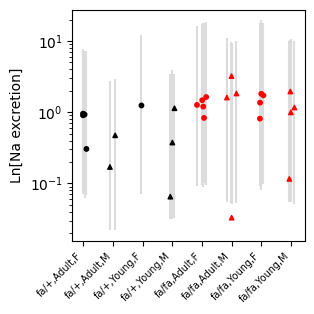

In [6]:
variable = "excretion_na_vehicle"
msts = pl.read_csv(f"../data/prepared/{variable}.csv")
idata = az.from_netcdf(f"../results/idata_{variable}.nc")
display(az.summary(idata, var_names=["~mu", "~sigma"]))
qlow, qhigh = idata.posterior_predictive["log_value"].quantile([0.025, 0.975], dim=["chain", "draw"]).to_numpy()

f, ax = plt.subplots(figsize=(3, 3))
ax, plot_df = plot_measurements(ax, msts)
ax.vlines(plot_df["scatter_x"], np.exp(qlow), np.exp(qhigh), zorder=-1, color="gainsboro");
plt.xticks(rotation=45, ha="right");
ax.semilogy()
ax.set_ylabel("Ln[Na excretion]")
# plt.savefig(PLOT_DIR / 'ppc_glc_excretion.pdf', bbox_inches='tight')

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,4.687,0.018,4.655,4.721,0.000,0.000,4695.0,3663.0,1.0
gtyp[fa/fa],-0.066,0.046,-0.150,0.023,0.001,0.001,2510.0,2372.0,1.0
age[Young],0.004,0.025,-0.041,0.052,0.000,0.000,3529.0,2459.0,1.0
sex[M],-0.036,0.024,-0.081,0.008,0.000,0.000,3217.0,2511.0,1.0
"gtyp:age[fa/fa, Young]",-0.012,0.058,-0.127,0.090,0.001,0.001,3295.0,2750.0,1.0
"gtyp:sex[fa/fa, M]",0.087,0.057,-0.026,0.191,0.001,0.001,2621.0,2522.0,1.0
sigma_Intercept,-3.023,0.199,-3.370,-2.649,0.003,0.003,3484.0,2995.0,1.0
sigma_gtyp[fa/fa],0.769,0.263,0.301,1.266,0.004,0.004,3775.0,3053.0,1.0


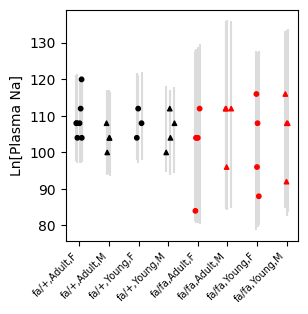

In [7]:
variable = "plasma_na_vehicle"
msts = pl.read_csv(f"../data/prepared/{variable}.csv")
idata = az.from_netcdf(f"../results/idata_{variable}.nc")
display(az.summary(idata, var_names=["~mu", "~sigma"]))
qlow, qhigh = idata.posterior_predictive["log_value"].quantile([0.025, 0.975], dim=["chain", "draw"]).to_numpy()

f, ax = plt.subplots(figsize=(3, 3))
ax, plot_df = plot_measurements(ax, msts)
ax.vlines(plot_df["scatter_x"], np.exp(qlow), np.exp(qhigh), zorder=-1, color="gainsboro");
ax.set_ylabel("Ln[Plasma Na]")
plt.xticks(rotation=45, ha="right");

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,1.374,0.290,0.802,1.893,0.006,0.005,2536.0,2474.0,1.0
gtyp[fa/fa],-1.047,0.431,-1.851,-0.227,0.009,0.007,2210.0,2622.0,1.0
age[Young],-0.366,0.415,-1.135,0.396,0.009,0.007,2294.0,2479.0,1.0
sex[M],-0.084,0.398,-0.825,0.645,0.009,0.007,1873.0,2500.0,1.0
"gtyp:age[fa/fa, Young]",0.016,0.568,-1.033,1.116,0.012,0.010,2110.0,2428.0,1.0
"gtyp:sex[fa/fa, M]",0.271,0.563,-0.825,1.285,0.013,0.009,1771.0,2768.0,1.0


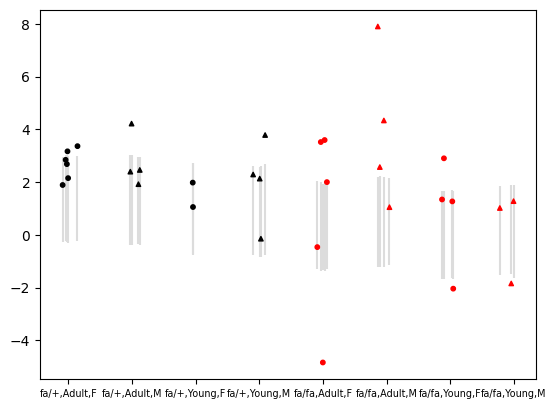

In [8]:
variable = "excretion_glucose_empa_minus_vehicle"
msts = pl.read_csv(f"../data/prepared/{variable}.csv")
idata = az.from_netcdf(f"../results/idata_{variable}.nc")
display(az.summary(idata, var_names=["~mu", "~sigma"]))
qlow, qhigh = idata.posterior_predictive["value"].quantile([0.025, 0.975], dim=["chain", "draw"]).to_numpy()

f, ax = plt.subplots()
ax, plot_df = plot_measurements(ax, msts)
ax.vlines(plot_df["scatter_x"], qlow, qhigh, zorder=-1, color="gainsboro");


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,0.029,0.284,-0.523,0.553,0.006,0.005,2625.0,2448.0,1.0
gtyp[fa/fa],0.263,0.357,-0.381,0.971,0.007,0.006,2406.0,2205.0,1.0
age[Young],0.140,0.427,-0.673,0.947,0.010,0.010,1886.0,1836.0,1.0
sex[M],-0.087,0.418,-0.833,0.756,0.009,0.009,2019.0,1948.0,1.0
"gtyp:age[fa/fa, Young]",-0.433,0.510,-1.461,0.434,0.012,0.010,1915.0,1998.0,1.0
"gtyp:sex[fa/fa, M]",0.563,0.506,-0.315,1.619,0.011,0.010,2101.0,2052.0,1.0
sigma_Intercept,-0.544,0.270,-1.018,-0.024,0.006,0.005,2117.0,2218.0,1.0
sigma_gtyp[fa/fa],0.001,0.327,-0.618,0.614,0.006,0.005,2867.0,2701.0,1.0


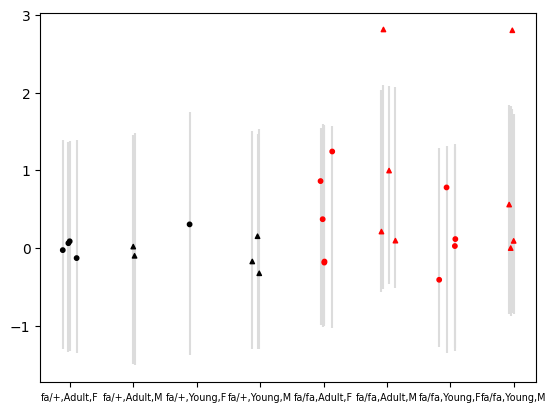

In [9]:
variable = "excretion_na_empa_minus_vehicle"
msts = pl.read_csv(f"../data/prepared/{variable}.csv")
idata = az.from_netcdf(f"../results/idata_{variable}.nc")
display(az.summary(idata, var_names=["~mu", "~sigma"]))
qlow, qhigh = idata.posterior_predictive["value"].quantile([0.025, 0.975], dim=["chain", "draw"]).to_numpy()

f, ax = plt.subplots()
ax, plot_df = plot_measurements(ax, msts)
ax.vlines(plot_df["scatter_x"], qlow, qhigh, zorder=-1, color="gainsboro");


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,0.046,0.029,-0.011,0.098,0.001,0.000,3040.0,2485.0,1.0
gtyp[fa/fa],0.089,0.045,0.007,0.172,0.001,0.001,2219.0,2555.0,1.0
age[Young],0.003,0.043,-0.080,0.078,0.001,0.001,2745.0,2629.0,1.0
sex[M],0.039,0.041,-0.040,0.112,0.001,0.001,2249.0,2640.0,1.0
"gtyp:age[fa/fa, Young]",0.000,0.059,-0.117,0.109,0.001,0.001,2643.0,2785.0,1.0
"gtyp:sex[fa/fa, M]",-0.084,0.059,-0.194,0.026,0.001,0.001,2117.0,2424.0,1.0


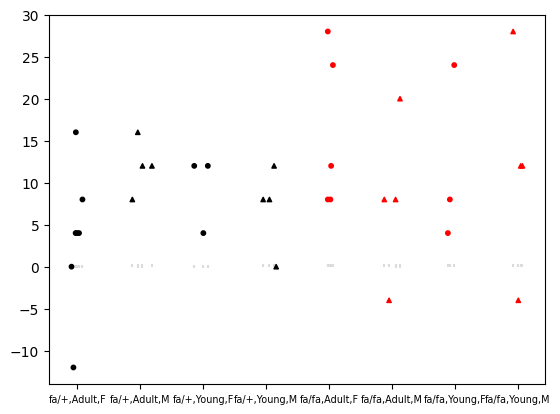

In [10]:
variable = "plasma_na_empa_minus_vehicle"
msts = pl.read_csv(f"../data/prepared/{variable}.csv")
idata = az.from_netcdf(f"../results/idata_{variable}.nc")
display(az.summary(idata, var_names=["~mu", "~sigma"]))
qlow, qhigh = idata.posterior_predictive["value"].quantile([0.025, 0.975], dim=["chain", "draw"]).to_numpy()

f, ax = plt.subplots()
ax, plot_df = plot_measurements(ax, msts)
ax.vlines(plot_df["scatter_x"], qlow, qhigh, zorder=-1, color="gainsboro");